# A colour–magnitude window for ultra-faint dwarfs: what it is and how to use it

Two things came back from the IAC visit:

1. **A selection window** in the Gaia colour–magnitude diagram, written as a TOPCAT expression —
   a 16-corner polygon in de-reddened colour (BP − RP)₀ against absolute magnitude M_G.
2. **A file**, `ufd_battaglia_gaia_ed3.dat`: the synthetic stellar population the polygon was drawn
   around, the same one used in Battaglia et al. 2022.

The idea is simple. An ultra-faint dwarf (UFD) is an old, metal-poor stellar population, and such
a population occupies a narrow, known track in the colour–magnitude diagram (CMD). Stars off that
track cannot be members. The window is that track with some room around it.

This notebook goes through it in order:

| § | Question |
|---|---|
| 1 | What is in the file? |
| 2 | What does the population look like in the CMD? |
| 3 | What exactly is the window, and how do I apply it? |
| 4 | Does it work on a real dwarf? (Reticulum II) |
| 5 | What changes with distance, and what if the distance is unknown? |
| 6 | How do I rebuild or change the window? (the reason the file was sent) |
| 7 | What can it not do, and what do I send to colleagues? |

**Self-contained.** The notebook needs only numpy, scipy, pandas, matplotlib and astropy, and the
`.dat` file next to it or in `../../materials/`. §4–6 download three small tables once (Gaia, a member list, a reddening value) and
cache them; without a connection those cells say so and the rest still runs.

In [1]:
import io, os, re, glob, inspect, importlib.util, urllib.parse, urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from matplotlib.path import Path as Polygon
from scipy import ndimage
import contourpy                      # ships with matplotlib
from astropy.table import Table

## Setup

In [4]:
# --- the two things that were sent
DAT = next(p for p in (Path('ufd_battaglia_gaia_ed3.dat'),
                       Path('../../materials/ufd_battaglia_gaia_ed3.dat')) if p.exists())

TOPCAT_EXPR = ('isInside(col11-col12, col10, -0.110,-0.01, 0.775,-0.19, 1.163,-3.21, 1.597,-3.26, '
               '1.258,-0.45, 1.048,3.25, 0.732,3.76, 1.600,8.00, 1.129,7.91, 0.628,5.75, 0.318,3.18, '
               '0.709,1.80, 0.697,1.30, 0.102,1.14, -0.113,2.12, -0.110,0.04)')

# --- where things are written
WORK   = DAT.parent / 'ufd_cmd_window'            # files to forward + the download cache
CACHE  = WORK / 'cache'
FIGDIR = (DAT.parent.parent / 'figures' / 'ufd_cmd_window') if DAT.parent.name == 'materials' else WORK / 'figures'
for d in (CACHE, FIGDIR):
    d.mkdir(parents=True, exist_ok=True)

# --- the worked example: Reticulum II
RETII_RA, RETII_DEC = 53.9254, -54.0492           # deg, ICRS
RETII_DIST_KPC      = 31.6                        # literature value; the largest unchecked input here
RETII_MU            = 5 * np.log10(RETII_DIST_KPC * 1e3) - 5      # distance modulus
CONE_RADIUS_DEG     = 1.0

# Extinction per unit E(B-V) in the Gaia bands: A_X = R_X * E(B-V).
# Casagrande & VandenBerg (2018, MNRAS 479, L102).
# section 4 shows how little the choice matters at this reddening.
R_EXT = dict(G=2.740, BP=3.374, RP=2.035)

GAIA_LIMIT = 21.0                                 # G, roughly where Gaia's catalogue ends
RNG = np.random.default_rng(0)

print(f'population file : {DAT}')
print(f'exports + cache : {WORK}')
print(f'figures         : {FIGDIR}')
print(f'Reticulum II    : {RETII_DIST_KPC} kpc  ->  distance modulus {RETII_MU:.2f}')

population file : ../../materials/ufd_battaglia_gaia_ed3.dat
exports + cache : ../../materials/ufd_cmd_window
figures         : ../../figures/ufd_cmd_window
Reticulum II    : 31.6 kpc  ->  distance modulus 17.50


In [5]:
# One plotting style for the whole notebook: plain matplotlib, nothing imported.
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 200, 'font.size': 11,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.linewidth': 0.8, 'axes.labelsize': 11, 'axes.titlesize': 11, 'axes.titleweight': 'normal',
    'xtick.direction': 'out', 'ytick.direction': 'out', 'legend.frameon': False, 'legend.fontsize': 9.5,
    'lines.linewidth': 1.8,
})
INK, MUTED = '#1A1A1A', '#6E6E6E'
C = dict(window='#D55E00',     # the received window          (Okabe-Ito, colour-blind safe)
         member='#0072B2',     # stars known to belong to the dwarf
         alt='#009E73',        # a window built in this notebook
         other='#CC79A7',      # a second group of stars
         field='#9A9A9A')      # everything else
HESS = 'Greys'                 # star counts: one hue, light to dark


def save(fig, name):
    fig.savefig(FIGDIR / f'{name}.png', bbox_inches='tight')


def hess(ax, colour, mag, *, xlim=(-0.4, 1.9), ylim=(9.0, -4.0), dx=0.02, dy=0.05):
    '''Star counts in the colour-magnitude plane, log-scaled. Brighter is up.'''
    xe = np.arange(xlim[0], xlim[1] + dx, dx)
    ye = np.arange(min(ylim), max(ylim) + dy, dy)
    H = np.histogram2d(colour, mag, bins=[xe, ye])[0].T
    mesh = ax.pcolormesh(xe, ye, np.where(H > 0, H, np.nan), cmap=HESS,
                         norm=LogNorm(vmin=0.6, vmax=np.nanmax(H)), rasterized=True)
    ax.set(xlim=xlim, ylim=ylim)
    return mesh


def outline(ax, vertices, **kw):
    '''Draw a closed polygon given its corners.'''
    v = np.vstack([vertices, vertices[:1]])
    return ax.plot(v[:, 0], v[:, 1], **kw)[0]

---
## 1 · What is in the file

The file starts with a commented header that describes itself. Read it first.

In [6]:
with open(DAT) as f:
    header = []
    for line in f:
        if not line.startswith('#'):
            break
        header.append(line.rstrip())
print('\n'.join(header))

##########################################
#     STAR FORMATION HISTORY
#
# t(Gyr)relative SFR [Fe/H]sigma([Fe/H])
# 12.00000  1.00000 -2.30000  0.50000
# 13.00000  1.00000 -2.30000  0.50000
##########################################
#Columns
#( 1) star number (+ 2 if unres. binary)
#( 2) log(t) years
#( 3) [Fe/H]
#( 4) value of evolving mass in Mo
#( 5) log(L/Lo)
#( 6) log(Teff)
#( 7) initial mass of unresolved
# secondary (in Mo) if different from 0.0
#( 8) Index variable star type (0 no var)
#( 9) log(P) in days of pulsating stars
#  if different from 99.99
##########################################
#G       G_BP    G_RP
##########################################
#(10) G
#(11) G_BP
#(12) G_RP
##########################################


So each row is one synthetic star, drawn from a single episode of star formation: constant rate
between 12 and 13 Gyr ago, metallicity [Fe/H] = −2.3 with a spread of 0.5 dex. The header layout
is that of the IAC-Star population-synthesis code. The last three columns are **absolute**
magnitudes in the three Gaia bands — the star as it would appear from 10 pc with no dust.

Column 10, 11, 12 are what the TOPCAT expression calls `col10`, `col11`, `col12`.

In [7]:
COLUMNS = ['star', 'log_age', 'feh', 'mass', 'logL', 'logTeff', 'm_secondary', 'var_type', 'logP',
           'G', 'BP', 'RP']
pop = pd.DataFrame(np.loadtxt(DAT), columns=COLUMNS)
pop['bp_rp'] = pop.BP - pop.RP
pop['age_gyr'] = 10 ** pop.log_age / 1e9

print(f'{len(pop):,} stars\n')
print(pop[['age_gyr', 'feh', 'mass', 'G', 'bp_rp']].describe().loc[['min', '50%', 'max']].round(3).to_string())

print(f'\nunresolved binaries (secondary mass > 0): {(pop.m_secondary > 0).sum()}')
print(f'variable stars flagged                  : {(pop.var_type != 0).sum()}')
print(f'\n[Fe/H]: mean {pop.feh.mean():.2f}, standard deviation {pop.feh.std():.2f}, '
      f'16th-84th percentile {pop.feh.quantile(0.16):.2f} to {pop.feh.quantile(0.84):.2f}')
print(f'stars more metal-rich than [Fe/H] = -1  : {(pop.feh > -1).sum()}  ({(pop.feh > -1).mean():.2%})')

237,000 stars

     age_gyr    feh   mass      G  bp_rp
min   12.000 -4.913  0.500 -3.105 -0.103
50%   12.495 -2.267  0.611  6.227  0.868
max   13.000  0.994  0.932  8.150  1.581

unresolved binaries (secondary mass > 0): 0
variable stars flagged                  : 0

[Fe/H]: mean -2.26, standard deviation 0.68, 16th-84th percentile -2.94 to -1.58
stars more metal-rich than [Fe/H] = -1  : 8314  (3.51%)


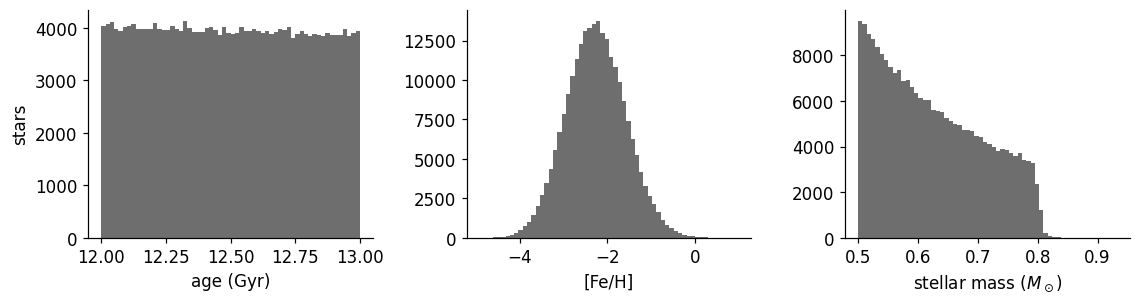

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(10.5, 2.9))
for a, col, lab in zip(ax, ['age_gyr', 'feh', 'mass'],
                       ['age (Gyr)', '[Fe/H]', r'stellar mass ($M_\odot$)']):
    a.hist(pop[col], bins=60, color=MUTED)
    a.set_xlabel(lab)
ax[0].set_ylabel('stars')
fig.tight_layout()
save(fig, '01_population_properties')

**What the file is, in one paragraph.** 237,000 stars, all between 12 and 13 Gyr old, centred on
[Fe/H] = −2.3. That is a textbook ultra-faint dwarf.

One thing to know about the metallicities: the header says σ = 0.5, but the stars' [Fe/H] has a
standard deviation of 0.68 — 3.5% of them are above [Fe/H] = −1, where a 0.5-dex Gaussian would
put 0.5%. How the code applies its dispersion is not stated in the file. In
practice the population is somewhat broader in metallicity, and therefore in colour, than the
header suggests.

**What it is not** — each of these matters later:

- **No binaries.** Column 7 is zero everywhere. Real unresolved binaries sit up to 0.75 mag above
  the main sequence and slightly redward.
- **No variables flagged**, so RR Lyrae are not marked (they are simply horizontal-branch stars here).
- **No photometric errors and no dust.** The sequences are as thin as theory makes them.
- **Nothing below 0.5 M☉.** The mass histogram stops dead there, so the main sequence ends
  artificially at M_G ≈ 8.15. Fainter dwarfs exist; they are just not in the file.
- **Only Gaia bands.** The window can be redone in another *Gaia* colour (§6), not in another
  photometric system.

> **Takeaway.** The file is a noise-free model of one old, metal-poor population in Gaia's three bands.

---
## 2 · The population in the colour–magnitude diagram

Colour on the x-axis (blue left, red right), absolute magnitude on the y-axis with **bright at
the top**. The grey scale is the number of stars per pixel, on a log scale, because the faint main
sequence outnumbers everything else by orders of magnitude.

brighter than M_G =   0:     514 stars  ( 0.22%)
brighter than M_G =   2:   2,558 stars  ( 1.08%)
brighter than M_G = 3.5:   9,049 stars  ( 3.82%)
brighter than M_G =   5:  47,071 stars  (19.86%)


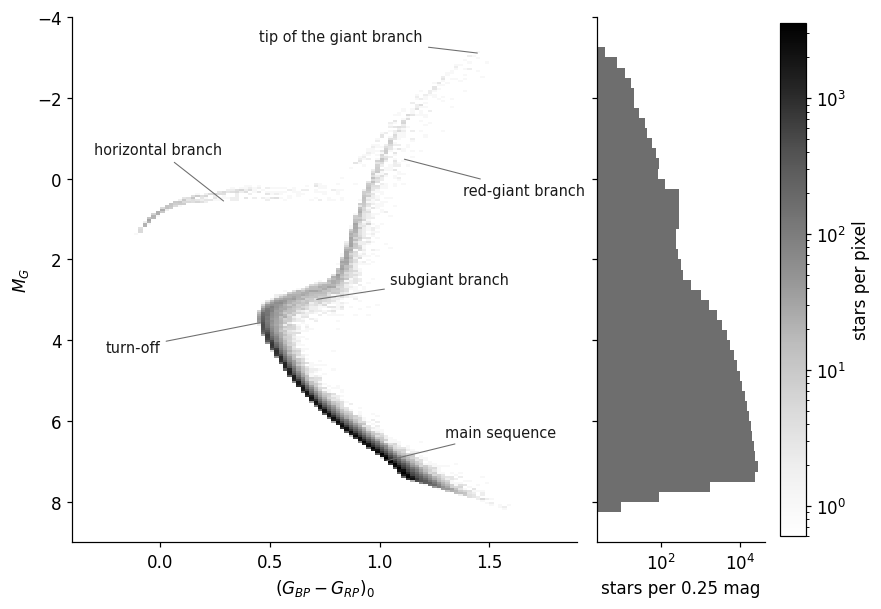

In [9]:
fig, (ax, lf) = plt.subplots(1, 2, figsize=(8.6, 6.2), sharey=True,
                             gridspec_kw=dict(width_ratios=[3, 1], wspace=0.06))
mesh = hess(ax, pop.bp_rp, pop.G)
ax.set(xlabel=r'$(G_{BP}-G_{RP})_0$', ylabel=r'$M_G$')

for text, xy, xytext in [
        ('main sequence',          (1.02, 7.0),  (1.30, 6.4)),
        ('turn-off',               (0.47, 3.55), (-0.25, 4.3)),
        ('subgiant branch',        (0.70, 3.0),  (1.05, 2.6)),
        ('red-giant branch',       (1.10, -0.5), (1.38, 0.4)),
        ('tip of the giant branch', (1.46, -3.1), (0.45, -3.4)),
        ('horizontal branch',      (0.30, 0.6),  (-0.30, -0.6))]:
    ax.annotate(text, xy=xy, xytext=xytext, color=INK, fontsize=9.5,
                arrowprops=dict(arrowstyle='-', color=MUTED, lw=0.7))

lf.hist(pop.G, bins=np.arange(-4, 9.01, 0.25), orientation='horizontal', color=MUTED)
lf.set(xscale='log', xlabel='stars per 0.25 mag')
fig.colorbar(mesh, ax=[ax, lf], label='stars per pixel', pad=0.02, fraction=0.035)
save(fig, '02_population_cmd')

for lim in (0, 2, 3.5, 5):
    print(f'brighter than M_G = {lim:>3}: {(pop.G < lim).sum():7,d} stars  ({(pop.G < lim).mean():6.2%})')

Reading the diagram from the bottom up, which is also the order of a star's life:

- **Main sequence** — hydrogen burning in the core. Lower-mass stars are fainter and redder.
- **Turn-off**, at M_G ≈ 3.5 and colour ≈ 0.47 — the bluest point. Stars more massive than this
  have already left the main sequence. Its position is the population's age clock.
- **Subgiant branch** — a quick, nearly horizontal move to the red.
- **Red-giant branch** — a steep climb to M_G ≈ −3.1 at the tip.
- **Horizontal branch**, near M_G ≈ 0.6 — core helium burning. It is *detached* from the rest and
  reaches far to the blue. At a fixed absolute magnitude, it is the best distance marker here.

The right-hand panel is the point to keep in mind for §5: **the bright stars are rare.** Only
about 1% of the file is brighter than M_G = 2, and under 4% is brighter than the turn-off.

> **Takeaway.** One old population is one thin, curved track plus a detached horizontal branch.

---
## 3 · The window

TOPCAT's `isInside(x, y, x1, y1, x2, y2, …)` is true where the point (x, y) lies inside the
polygon with corners (x1, y1), (x2, y2), … The expression received was written for this very
file, so `col11-col12` is BP − RP and `col10` is G:

```
isInside(col11-col12, col10, -0.110,-0.01, 0.775,-0.19, 1.163,-3.21, …)
          └─ colour ─┘ └ M_G ┘ └ corner 1 ┘ └ corner 2 ┘ └ corner 3 ┘
```

Two small functions turn that string into corners and back.

In [10]:
def parse_isinside(expr):
    '''TOPCAT isInside(x, y, x1, y1, ...) -> (x expression, y expression, corners as an (n, 2) array).'''
    inner = re.fullmatch(r'\s*isInside\((.*)\)\s*', expr, flags=re.S).group(1)
    parts = [p.strip() for p in inner.split(',')]
    return parts[0], parts[1], np.array(parts[2:], float).reshape(-1, 2)


def to_isinside(vertices, x_expr, y_expr):
    '''Corners -> the TOPCAT expression, for whatever the columns are called in your table.'''
    pairs = ', '.join(f'{x:.3f},{y:.2f}' for x, y in vertices)
    return f'isInside({x_expr}, {y_expr}, {pairs})'


x_expr, y_expr, UFD_WINDOW = parse_isinside(TOPCAT_EXPR)
print(f'x = {x_expr}    y = {y_expr}    {len(UFD_WINDOW)} corners\n')
print(pd.DataFrame(UFD_WINDOW, columns=['(BP-RP)_0', 'M_G'], index=range(1, len(UFD_WINDOW) + 1)).T.to_string())

assert to_isinside(UFD_WINDOW, x_expr, y_expr) == TOPCAT_EXPR, 'the string does not round-trip'

x = col11-col12    y = col10    16 corners

             1      2      3      4      5      6      7    8      9      10     11     12     13     14     15    16
(BP-RP)_0 -0.11  0.775  1.163  1.597  1.258  1.048  0.732  1.6  1.129  0.628  0.318  0.709  0.697  0.102 -0.113 -0.11
M_G       -0.01 -0.190 -3.210 -3.260 -0.450  3.250  3.760  8.0  7.910  5.750  3.180  1.800  1.300  1.140  2.120  0.04


Applying it is a point-in-polygon test. This is the function to keep:

In [11]:
def in_window(colour0, abs_mag, vertices):
    '''True where (de-reddened colour, absolute magnitude) lies inside the polygon `vertices`.

    A star with a missing colour or magnitude (NaN) is outside.'''
    colour0, abs_mag = np.asarray(colour0, float), np.asarray(abs_mag, float)
    pts = np.column_stack([colour0.ravel(), abs_mag.ravel()])
    return Polygon(vertices).contains_points(pts).reshape(colour0.shape)


pop['inside'] = in_window(pop.bp_rp, pop.G, UFD_WINDOW)
print(f'inside the window: {pop.inside.sum():,} of {len(pop):,}  ({pop.inside.mean():.3%})')
print('\nthe stars left out:')
print(pop.loc[~pop.inside, ['bp_rp', 'G', 'mass']].round(3).to_string())

assert len(UFD_WINDOW) == 16 and pop.inside.sum() == 236_989

inside the window: 236,989 of 237,000  (99.995%)

the stars left out:
        bp_rp      G   mass
60939   1.493  8.026  0.502
68969   1.548  8.121  0.505
69803   0.817  3.743  0.893
82171   1.568  8.129  0.513
93569   1.517  8.070  0.502
118443  1.581  8.068  0.528
156606  1.578  8.137  0.516
167042  1.501  8.009  0.507
170342  1.550  8.086  0.514
191297  1.562  8.150  0.507
205170  1.505  8.005  0.510


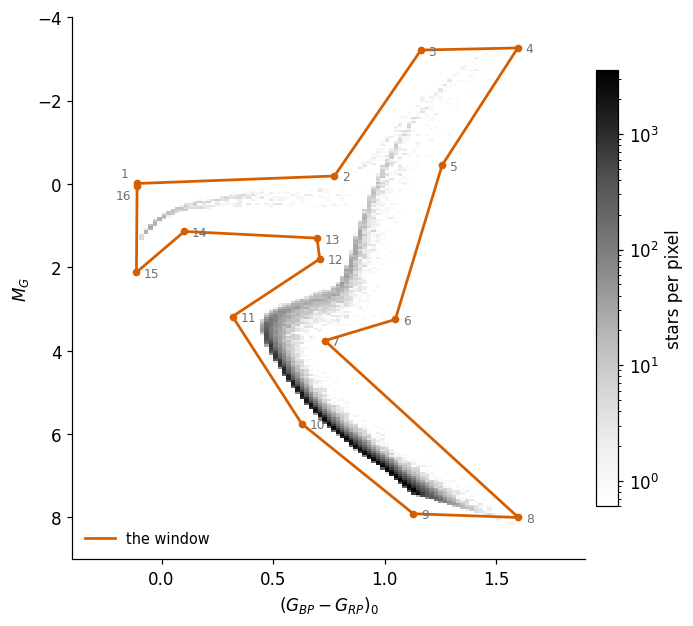

In [12]:
fig, ax = plt.subplots(figsize=(6.4, 6.4))
mesh = hess(ax, pop.bp_rp, pop.G)
outline(ax, UFD_WINDOW, color=C['window'], lw=1.8, label='the window')
ax.plot(*UFD_WINDOW.T, 'o', ms=4, color=C['window'])
for i, (x, y) in enumerate(UFD_WINDOW, 1):
    ax.annotate(str(i), (x, y), textcoords='offset points', fontsize=8, color=MUTED,
                xytext={1: (-11, 4), 16: (-14, -9)}.get(i, (5, -3)))
ax.set(xlabel=r'$(G_{BP}-G_{RP})_0$', ylabel=r'$M_G$')
ax.legend(loc='lower left')
fig.colorbar(mesh, ax=ax, label='stars per pixel', pad=0.02, fraction=0.04)
save(fig, '03_window_on_population')

The window holds 236,989 of the 237,000 stars. Ten of the eleven left out are the very faintest
(the polygon is closed off at M_G ≈ 8, the file runs to 8.15); the other one clips a concave
corner. So this is an **envelope drawn by hand around the population**, including a separate arm
for the horizontal branch (corners 12–16 and 1).

It is not a tight envelope. The room it leaves is measured below, per magnitude: how far the
polygon's edge is from the population's edge, on the blue side and on the red side.

In [13]:
def polygon_colour_range(vertices, mag):
    '''The polygon's bluest and reddest colour at a given magnitude.'''
    xs = []
    for (x1, y1), (x2, y2) in zip(vertices, np.roll(vertices, -1, axis=0)):
        if (y1 - mag) * (y2 - mag) < 0:
            xs.append(x1 + (mag - y1) * (x2 - x1) / (y2 - y1))
    return (min(xs), max(xs)) if xs else (np.nan, np.nan)


rows = []
for m in [-2.5, -1.5, -0.5, 2.5, 3.5, 4.5, 5.5, 6.5, 7.5]:       # skipping the horizontal-branch arm
    s = pop[(pop.G > m - 0.25) & (pop.G < m + 0.25)]
    lo, hi = polygon_colour_range(UFD_WINDOW, m)
    rows.append(dict(M_G=m, stars=len(s), pop_blue=s.bp_rp.quantile(0.005), pop_red=s.bp_rp.quantile(0.995),
                     room_blue=s.bp_rp.quantile(0.005) - lo, room_red=hi - s.bp_rp.quantile(0.995)))
room = pd.DataFrame(rows)
print(room.round(3).to_string(index=False))
print(f'\nmedian room on the blue side: {room.room_blue.median():.2f} mag   on the red side: {room.room_red.median():.2f} mag')

 M_G  stars  pop_blue  pop_red  room_blue  room_red
-2.5     31     1.243    1.464      0.171     0.042
-1.5     70     1.043    1.238      0.099     0.146
-0.5    166     0.887    1.151      0.072     0.113
 2.5    945     0.661    0.917      0.150     0.174
 3.5   5981     0.455    0.685      0.098     0.208
 4.5  14792     0.523    0.640      0.045     0.243
 5.5  27453     0.659    0.798      0.061     0.290
 6.5  41170     0.859    1.035      0.057     0.258
 7.5  25220     1.098    1.328      0.064     0.169

median room on the blue side: 0.07 mag   on the red side: 0.17 mag


(Between M_G ≈ −0.2 and 2.4 the polygon's blue edge is the horizontal-branch arm, so those
magnitudes are skipped.)

The room is **lopsided**: a median of 0.07 mag on the blue side against 0.17 mag on the red, and
along the main sequence the red margin is four to five times the blue one. A red margin is what
you would leave for things the model lacks — unresolved binaries, somewhat more metal-rich stars,
dust that was under-corrected — all of which move a star redward. That reading is mine; it did
not come with the file. The one place the window is tight on the red side is the tip of the giant
branch (0.04 mag at M_G = −2.5).

> **Takeaway.** The window is a hand-drawn, generous envelope of the population, with extra room to the red.

---
## 4 · Applying it to real stars: Reticulum II

The window is in **absolute** magnitude and **de-reddened** colour. A catalogue gives neither, so
two corrections come first:

$$M_G = G - A_G - \mu, \qquad (G_{BP}-G_{RP})_0 = (G_{BP}-G_{RP}) - (A_{BP}-A_{RP})$$

- **μ, the distance modulus**, 5 log₁₀(d / 10 pc). You must supply a distance. For Reticulum II at
  31.6 kpc, μ = 17.50.
- **A_X, the extinction** in each band, here R_X × E(B−V) with E(B−V) from a dust map.

That is all the next function does.

In [14]:
def absolute_cmd(G, BP, RP, dist_mod, ebv=0.0, R=R_EXT):
    '''Observed Gaia magnitudes -> (de-reddened BP-RP colour, absolute G magnitude).

    dist_mod : distance modulus, 5 log10(d / 10 pc)
    ebv      : reddening E(B-V), a number or one value per star
    R        : extinction per unit E(B-V) in each band'''
    G, BP, RP = (np.asarray(v, float) for v in (G, BP, RP))
    colour0 = (BP - RP) - (R['BP'] - R['RP']) * ebv
    abs_mag = G - R['G'] * ebv - dist_mod
    return colour0, abs_mag

### The data

Three small downloads, each cached, each over plain HTTP so no extra package is needed:

- every Gaia DR3 source within 1° of Reticulum II;
- the Battaglia et al. 2022 membership probabilities for Reticulum II (VizieR `J/A+A/657/A54`);
- the reddening at that position (IRSA dust service).

In [15]:
def tap_sync(url, adql, maxrec=500_000, timeout=300):
    '''Run one ADQL query on a TAP service and return an astropy Table.'''
    data = urllib.parse.urlencode(dict(REQUEST='doQuery', LANG='ADQL', FORMAT='csv',
                                       MAXREC=maxrec, QUERY=adql)).encode()
    with urllib.request.urlopen(f'{url}/sync', data=data, timeout=timeout) as r:
        return Table.read(io.BytesIO(r.read()), format='ascii.csv')


def cached(path, fetch):
    '''Read `path` if it exists; otherwise fetch, save and return. None if the service cannot be reached.'''
    if path.exists():
        return Table.read(path, format='ascii.ecsv')
    try:
        t = fetch()
    except Exception as e:
        print(f'could not fetch {path.name}: {type(e).__name__}: {e}')
        return None
    t.write(path, format='ascii.ecsv')
    return t


GAIA_TAP   = ['https://gea.esac.esa.int/tap-server/tap', 'https://gaia.ari.uni-heidelberg.de/tap']
VIZIER_TAP = 'https://tapvizier.cds.unistra.fr/TAPVizieR/tap'

def fetch_cone():
    where = (f"1 = CONTAINS(POINT('ICRS', ra, dec), "
             f"CIRCLE('ICRS', {RETII_RA}, {RETII_DEC}, {CONE_RADIUS_DEG}))")
    cols = ('source_id, ra, dec, pmra, pmdec, parallax, parallax_error, phot_g_mean_mag, '
            'phot_bp_mean_mag, phot_rp_mean_mag, phot_g_mean_flux_over_error, '
            'phot_bp_mean_flux_over_error, phot_rp_mean_flux_over_error')
    for url in GAIA_TAP:                                   # the ESA archive, then a mirror
        try:
            n = int(tap_sync(url, f'SELECT COUNT(*) AS n FROM gaiadr3.gaia_source WHERE {where}')['n'][0])
            t = tap_sync(url, f'SELECT {cols} FROM gaiadr3.gaia_source WHERE {where}')
            assert len(t) == n, f'{url} returned {len(t)} of {n} rows'      # a silently truncated result
            return t
        except Exception as e:
            print(f'{url}: {type(e).__name__}: {e}')
    raise ConnectionError('no Gaia TAP service answered')

def fetch_members():
    return tap_sync(VIZIER_TAP, '''SELECT Galaxy, GaiaEDR3, RA_ICRS, DE_ICRS, Pmemb
                                   FROM "J/A+A/657/A54/pmem" WHERE Galaxy = 'ReticulumII' ''')

def fetch_ebv():
    url = ('https://irsa.ipac.caltech.edu/cgi-bin/DUST/nph-dust?locstr='
           f'{RETII_RA}+{RETII_DEC}+equ+j2000')
    xml = urllib.request.urlopen(url, timeout=60).read().decode()
    val = lambda tag: float(re.search(rf'<{tag}>\s*([-\d.]+)', xml).group(1))
    return Table(dict(ebv_sandf=[val('meanValueSandF')], ebv_sfd=[val('meanValueSFD')]))


cone    = cached(CACHE / 'retii_gaia_dr3_cone_1deg.ecsv', fetch_cone)
members = cached(CACHE / 'retii_battaglia22_pmemb.ecsv',  fetch_members)
dust    = cached(CACHE / 'retii_irsa_ebv.ecsv',           fetch_ebv)

HAVE_DATA = cone is not None and members is not None
if dust is None:
    EBV = 0.016
    print('reddening service unreachable: using E(B-V) = 0.016 (the value it returned on 2026-10-08)')
else:
    EBV = float(dust['ebv_sandf'][0])                       # Schlafly & Finkbeiner 2011 scale
    print(f"E(B-V) at Reticulum II: {EBV:.4f} (Schlafly & Finkbeiner), {float(dust['ebv_sfd'][0]):.4f} (SFD)")
if HAVE_DATA:
    print(f'Gaia cone: {len(cone):,} sources    membership table: {len(members)} candidates')

E(B-V) at Reticulum II: 0.0155 (Schlafly & Finkbeiner), 0.0180 (SFD)
Gaia cone: 13,877 sources    membership table: 540 candidates


### How big are the two corrections?

Before using them, look at their size. The distance modulus moves every star by 17.5 mag. The
dust moves them by a few hundredths.

In [16]:
A = {b: R_EXT[b] * EBV for b in R_EXT}
print(f'distance modulus                 : {RETII_MU:6.2f} mag')
print(f'extinction in G                  : {A["G"]:6.3f} mag')
print(f'reddening of BP-RP               : {A["BP"] - A["RP"]:6.3f} mag')

# how much the answer depends on which extinction law is used
R_ALT = dict(G=2.4, BP=2.58, RP=1.65)          # the set used in this repo's fushimi_data_nb.ipynb
print(f'\nwith another published coefficient set the colour correction changes by '
      f'{abs((R_ALT["BP"] - R_ALT["RP"]) - (R_EXT["BP"] - R_EXT["RP"])) * EBV:.3f} mag here,')
print(f'but by {abs((R_ALT["BP"] - R_ALT["RP"]) - (R_EXT["BP"] - R_EXT["RP"])) * 0.3:.2f} mag at E(B-V) = 0.3.')

distance modulus                 :  17.50 mag
extinction in G                  :  0.042 mag
reddening of BP-RP               :  0.021 mag

with another published coefficient set the colour correction changes by 0.006 mag here,
but by 0.12 mag at E(B-V) = 0.3.


At Reticulum II the dust correction is smaller than the window's margins by a factor of several,
and the choice of extinction law is irrelevant. **That is a property of this field** (high
Galactic latitude), not of the method: at E(B−V) = 0.3 the law alone shifts colours by more than
the blue-side margin, and a single reddening value per field stops being good enough.

### The window on the Reticulum II field

In [17]:
if HAVE_DATA:
    g = cone.to_pandas()
    g = g.merge(members.to_pandas()[['GaiaEDR3', 'Pmemb']], how='left',
                left_on='source_id', right_on='GaiaEDR3').drop(columns='GaiaEDR3')
    g['Pmemb'] = g.Pmemb.fillna(0.0)
    g['member'] = g.Pmemb > 0.5

    g['has_colour'] = g.phot_bp_mean_mag.notna() & g.phot_rp_mean_mag.notna()
    g['colour0'], g['MG'] = absolute_cmd(g.phot_g_mean_mag, g.phot_bp_mean_mag, g.phot_rp_mean_mag,
                                         RETII_MU, EBV)
    g['inside'] = in_window(g.colour0, g.MG, UFD_WINDOW)

    # the star cuts the EagleEye dwarf search already applies (analyze_known_dwarfs.py)
    g['pm_plx'] = ((g.pmra.abs() <= 5) & (g.pmdec.abs() <= 5)
                   & ((g.parallax - 3 * g.parallax_error) < 0))

    print(f'{len(g):,} Gaia sources; {(~g.has_colour).sum():,} have no BP or RP magnitude '
          f'({(~g.has_colour).mean():.1%}) and cannot be placed in the diagram')
    print(f'members (Pmemb > 0.5): {g.member.sum()}, of which {g[g.member].has_colour.sum()} have a colour')

13,877 Gaia sources; 166 have no BP or RP magnitude (1.2%) and cannot be placed in the diagram
members (Pmemb > 0.5): 75, of which 75 have a colour


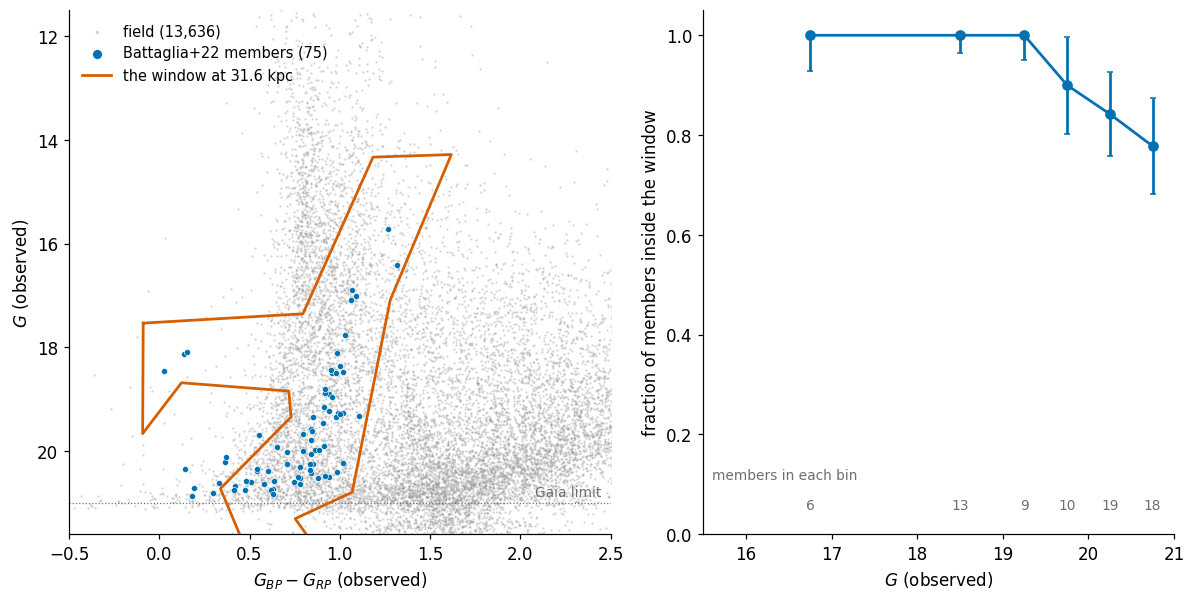

In [18]:
def window_observed(vertices, dist_mod, ebv=0.0, R=R_EXT):
    '''The window moved into observed (BP-RP, G) for a given distance and reddening.'''
    return vertices + np.array([(R['BP'] - R['RP']) * ebv, dist_mod + R['G'] * ebv])


def binomial_err(k, n):
    '''Half-width of a 68% Wilson interval, for an error bar on a fraction k/n.'''
    k, n = np.asarray(k, float), np.maximum(np.asarray(n, float), 1)
    p = k / n
    return np.sqrt(p * (1 - p) / n + 0.25 / n ** 2) / (1 + 1 / n)


if HAVE_DATA:
    fld, mem = g[~g.member & g.has_colour], g[g.member & g.has_colour]
    obs_window = window_observed(UFD_WINDOW, RETII_MU, EBV)

    fig, (ax, bx) = plt.subplots(1, 2, figsize=(11, 5.6), gridspec_kw=dict(width_ratios=[1.15, 1]))
    ax.scatter(fld.phot_bp_mean_mag - fld.phot_rp_mean_mag, fld.phot_g_mean_mag, s=2, color=C['field'],
               alpha=0.45, lw=0, rasterized=True, label=f'field ({len(fld):,})')
    ax.scatter(mem.phot_bp_mean_mag - mem.phot_rp_mean_mag, mem.phot_g_mean_mag, s=16, color=C['member'],
               edgecolors='white', lw=0.4, zorder=3, label=f'Battaglia+22 members ({len(mem)})')
    outline(ax, obs_window, color=C['window'], lw=1.8, zorder=4, label='the window at 31.6 kpc')
    ax.axhline(GAIA_LIMIT, color=MUTED, lw=0.8, ls=':')
    ax.text(2.45, GAIA_LIMIT - 0.08, 'Gaia limit', ha='right', va='bottom', fontsize=9, color=MUTED)
    ax.set(xlim=(-0.5, 2.5), ylim=(21.6, 11.5), xlabel=r'$G_{BP}-G_{RP}$ (observed)', ylabel=r'$G$ (observed)')
    ax.legend(loc='upper left', markerscale=1.6)

    # how many members the window keeps, by brightness
    edges = np.array([15.5, 18, 19, 19.5, 20, 20.5, 21])
    mid, frac, err = [], [], []
    for lo, hi in zip(edges[:-1], edges[1:]):
        s = mem[(mem.phot_g_mean_mag >= lo) & (mem.phot_g_mean_mag < hi)]
        if len(s):
            mid.append(0.5 * (lo + hi)); frac.append(s.inside.mean()); err.append(binomial_err(s.inside.sum(), len(s)))
            bx.text(mid[-1], 0.05, f'{len(s)}', ha='center', fontsize=9, color=MUTED)
    lower = np.minimum(err, frac); upper = np.minimum(err, 1 - np.array(frac))
    bx.errorbar(mid, frac, yerr=[lower, upper], fmt='o-', color=C['member'], ms=6, capsize=2)
    bx.text(edges[0] + 0.1, 0.11, 'members in each bin', ha='left', fontsize=9, color=MUTED)
    bx.set(xlim=(edges[0], edges[-1]), ylim=(0, 1.05), xlabel=r'$G$ (observed)',
           ylabel='fraction of members inside the window')
    fig.tight_layout()
    save(fig, '04_retii_window')

In [19]:
if HAVE_DATA:
    def report(label, sel):
        s = g[sel & g.has_colour]
        print(f'{label:46s} {len(s):6,d} stars   inside the window: {s.inside.sum():6,d}  ({s.inside.mean():6.1%})')

    report('members (Pmemb > 0.5)',                     g.member)
    report('members brighter than G = 19.5',            g.member & (g.phot_g_mean_mag < 19.5))
    report('members fainter than G = 20',               g.member & (g.phot_g_mean_mag > 20))
    print()
    report('field, no other cut',                       ~g.member)
    report('field, after the proper-motion/parallax cuts', ~g.member & g.pm_plx)

    f0 = g[~g.member & g.has_colour]
    f1 = f0[f0.pm_plx]
    print(f'\nof {len(f0):,} field stars, the proper-motion and parallax cuts keep {len(f1):,}; '
          f'adding the window keeps {f1.inside.sum():,}.')
    print(f'the window on its own removes {1 - f0.inside.mean():.0%} of the field; '
          f'on top of the other cuts it removes {1 - f1.inside.mean():.0%} of what is left.')

members (Pmemb > 0.5)                              75 stars   inside the window:     67  ( 89.3%)
members brighter than G = 19.5                     28 stars   inside the window:     28  (100.0%)
members fainter than G = 20                        37 stars   inside the window:     30  ( 81.1%)

field, no other cut                            13,636 stars   inside the window:  3,225  ( 23.7%)
field, after the proper-motion/parallax cuts    2,178 stars   inside the window:  1,071  ( 49.2%)

of 13,636 field stars, the proper-motion and parallax cuts keep 2,178; adding the window keeps 1,071.
the window on its own removes 76% of the field; on top of the other cuts it removes 51% of what is left.


What the figure and the numbers say:

- The known members follow the window's track, the three horizontal-branch stars included.
  **All 28 members brighter than G = 19.5 are inside.**
- **The loss is at the faint end**: 67 of 75 members overall, 30 of 37 fainter than G = 20. The
  ones lost sit just blueward of the turn-off.
- The window alone removes 76% of the field. But the dwarf search already removes nearby stars
  with its parallax and proper-motion cuts, and what survives those is the faint, distant,
  halo-like field that looks most like a dwarf in colour. **On top of those cuts the window
  removes 51%** — a factor of two, not four. That second number is the window's added value.
- 166 of the 13,877 Gaia sources (1.2%) have no BP or RP magnitude. They cannot be placed in the
  diagram and count as outside. No Reticulum II member is affected, but for a fainter or more
  distant dwarf this is a silent loss worth checking.

### Why the faint members fall out: photometric errors

The window was drawn on error-free photometry. Gaia's is not, and the errors can be read off the
catalogue itself: a magnitude error is 1.086 divided by the flux signal-to-noise.

        bp_rp   g_rp      g
G                          
18.125  0.027  0.011  0.001
19.125  0.062  0.021  0.003
20.125  0.128  0.048  0.005
20.625  0.196  0.087  0.009


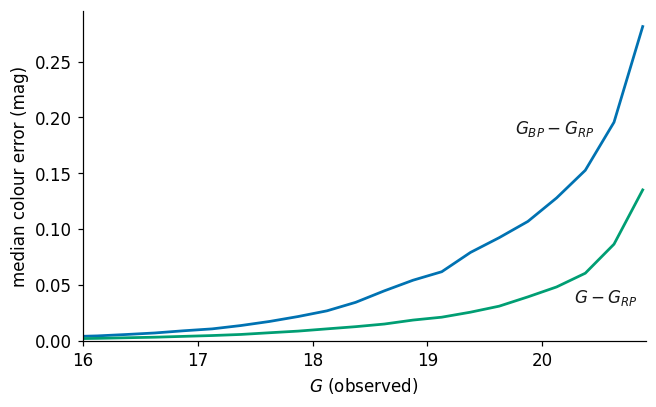

In [20]:
if HAVE_DATA:
    ok = g.has_colour & (g.phot_g_mean_mag > 14)
    sig = pd.DataFrame(dict(
        G=g.phot_g_mean_mag,
        bp_rp=1.0857 * np.hypot(1 / g.phot_bp_mean_flux_over_error, 1 / g.phot_rp_mean_flux_over_error),
        g_rp=1.0857 * np.hypot(1 / g.phot_g_mean_flux_over_error, 1 / g.phot_rp_mean_flux_over_error),
        g=1.0857 / g.phot_g_mean_flux_over_error))[ok]
    edges = np.arange(14, 21.01, 0.25)
    err_model = sig.groupby(pd.cut(sig.G, edges), observed=False)[['bp_rp', 'g_rp', 'g']].median()
    err_model.index = 0.5 * (edges[:-1] + edges[1:])
    err_model = err_model.dropna()

    def colour_err(G, which='bp_rp'):
        '''Median error of a colour ('bp_rp', 'g_rp') or of G itself ('g') at apparent magnitude G.'''
        return np.interp(G, err_model.index, err_model[which])

    fig, ax = plt.subplots(figsize=(6.6, 3.9))
    ax.plot(err_model.index, err_model.bp_rp, color=C['member'])
    ax.plot(err_model.index, err_model.g_rp,  color=C['alt'])
    ax.text(20.45, colour_err(20.45, 'bp_rp') + 0.02, r'$G_{BP}-G_{RP}$', ha='right', color=INK)
    ax.text(20.55, colour_err(20.55, 'g_rp') - 0.045, r'$G-G_{RP}$', ha='center', color=INK)
    ax.set(xlabel=r'$G$ (observed)', ylabel='median colour error (mag)', xlim=(16, 20.9), ylim=(0, None))
    save(fig, '05_colour_errors')
    print(err_model.loc[[18.125, 19.125, 20.125, 20.625]].round(3).rename_axis('G').to_string())

The BP − RP colour of a star is good to 0.03 mag at G = 18, 0.13 mag at G = 20 and 0.2 mag at
G = 20.6. Compare §3: the window's blue margin along the turn-off is 0.05–0.10 mag. So at G > 20
a member's colour error is larger than the room the window leaves on the blue side, and one-sigma
scatter is enough to push it out. That is the whole reason for the faint-end loss, and §6 builds
a window that accounts for it. (The second line, G − RP, is less than half as noisy; §6 uses that
too.)

### The same test on EagleEye's Reticulum II detections

If the EagleEye star list for Reticulum II is on disk (`$EE_DATA_DIR/gaia/`), put its two clusters
on the diagram: `cluster 1` is Reticulum II itself, `cluster 0` is the Reticulum+ 1.2° away. The error bars are the median colour error at each star's magnitude, from the curve above.

    G  bp_rp  colour_err   MG  inside
20.20   1.55        0.14 2.66   False
20.30   0.78        0.15 2.76    True
20.70   0.43        0.22 3.16    True
20.18   0.61        0.13 2.63    True
19.60   0.88        0.09 2.06    True
19.79   0.36        0.10 2.25   False


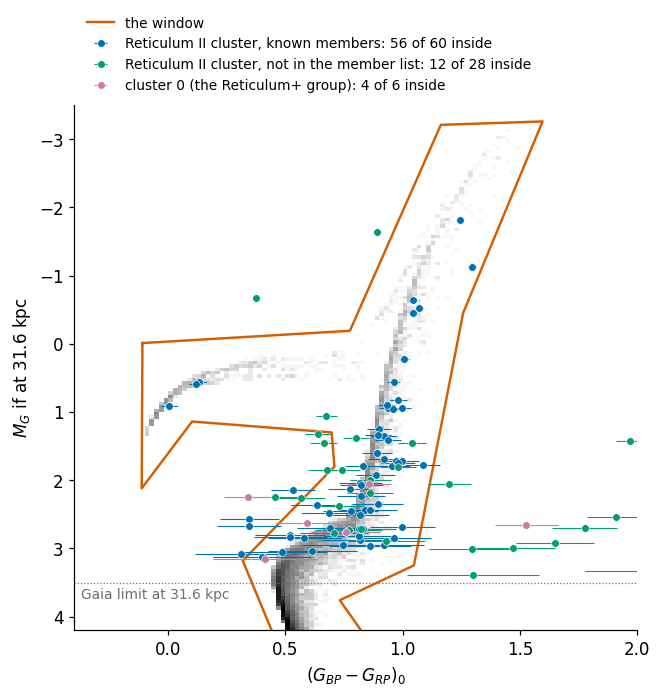

In [21]:
ee_files = sorted(glob.glob(os.path.join(os.environ.get('EE_DATA_DIR', os.path.expanduser('~/data/eagleeye_datasets')),
                                         'gaia', 'Reticulum_II_*_star_list_full.csv')))
ee = pd.read_csv(ee_files[0]) if ee_files else None

if ee is None:
    print('no EagleEye Reticulum II list found: skipped')
else:
    # the list has G and BP-RP; the window needs colour and absolute magnitude
    ee['colour0'] = ee.bp_rp - (R_EXT['BP'] - R_EXT['RP']) * EBV
    ee['MG']      = ee.G - R_EXT['G'] * EBV - RETII_MU
    ee['inside']  = in_window(ee.colour0, ee.MG, UFD_WINDOW)
    ee['known']   = ee.known_member.notna()

    ee['colour_err'] = colour_err(ee.G) if HAVE_DATA else np.nan

    groups = [('Reticulum II cluster, known members',  (ee.cluster == 'cluster 1') & ee.known,  C['member']),
              ('Reticulum II cluster, not in the member list', (ee.cluster == 'cluster 1') & ~ee.known, C['alt']),
              ('cluster 0 (the Reticulum+ group)',        ee.cluster == 'cluster 0',               C['other'])]

    fig, ax = plt.subplots(figsize=(6.6, 6.2))
    hess(ax, pop.bp_rp, pop.G, xlim=(-0.4, 2.0), ylim=(4.2, -3.5))
    outline(ax, UFD_WINDOW, color=C['window'], lw=1.6, label='the window')
    for label, sel, colour in groups:
        s = ee[sel]
        ax.errorbar(s.colour0, s.MG, xerr=s.colour_err, fmt='o', ms=5, color=colour, ecolor=colour,
                    elinewidth=0.7, mec='white', mew=0.4, zorder=4,
                    label=f'{label}: {s.inside.sum()} of {len(s)} inside')
    ax.axhline(GAIA_LIMIT - RETII_MU, color=MUTED, lw=0.8, ls=':')
    ax.text(-0.37, GAIA_LIMIT - RETII_MU + 0.08, 'Gaia limit at 31.6 kpc', ha='left', va='top', fontsize=9, color=MUTED)
    ax.set(xlabel=r'$(G_{BP}-G_{RP})_0$', ylabel=r'$M_G$ if at 31.6 kpc')
    ax.legend(loc='lower left', bbox_to_anchor=(0, 1.0), fontsize=9)
    save(fig, '06_eagleeye_retii_clusters')

    print(ee[ee.cluster == 'cluster 0'][['G', 'bp_rp', 'colour_err', 'MG', 'inside']].round(2).to_string(index=False))

Read this one with care:

- **Known members: 56 of 60 inside.** The four outside are faint and one to two error bars
  blueward of the window's edge — the same effect as above.
- **Stars EagleEye put in the Reticulum II cluster that are *not* in the member list: 12 of 28
  inside.** Most of the sixteen outside are nowhere near the track — far to the red, or well
  above it. Here the window does real work: it separates the list's likely contaminants from its
  likely members using information (colour and brightness) that the detection did not use.
- For **cluster 0**, the y-axis is M_G *if the stars are at Reticulum II's distance* — an
  assumption, since the list has no distances. Four of six are inside. Of the two outside, one is
  about 0.4 mag redder than the window, three error bars away, so it is not an old metal-poor
  star at that distance; the other is about 0.25 mag bluer than the edge, two error bars. With
  six stars this faint, **the window neither supports nor rules out a common origin with
  Reticulum II.** And §5 shows the assumed distance barely matters to that statement.

> **Takeaway.** To use the window you need a distance and a reddening. On a real dwarf it keeps
> the bright members and loses faint ones to photometric noise; what it adds on top of the
> existing proper-motion and parallax cuts is smaller than its raw rejection rate suggests.

---
## 5 · Distance, depth, and not knowing the distance

### How much of the population Gaia can see

Moving the population away slides it down the diagram: G = M_G + μ. Gaia stops near G ≈ 21, so
with distance the diagram is cut off from below — and because bright stars are rare (§2), most of
the population disappears quickly.

 d (kpc)    mu    faintest M_G seen   stars seen (of 237,000)   what is left
     30   17.4             3.6            10,468          giants, horizontal branch, down to the turn-off
     60   18.9             2.1             2,709          giants, horizontal branch, subgiants
    100   20.0             1.0             1,507          giants and the horizontal branch
    150   20.9             0.1               557          giants and the horizontal branch, barely
    250   22.0            -1.0               203          the upper giant branch only


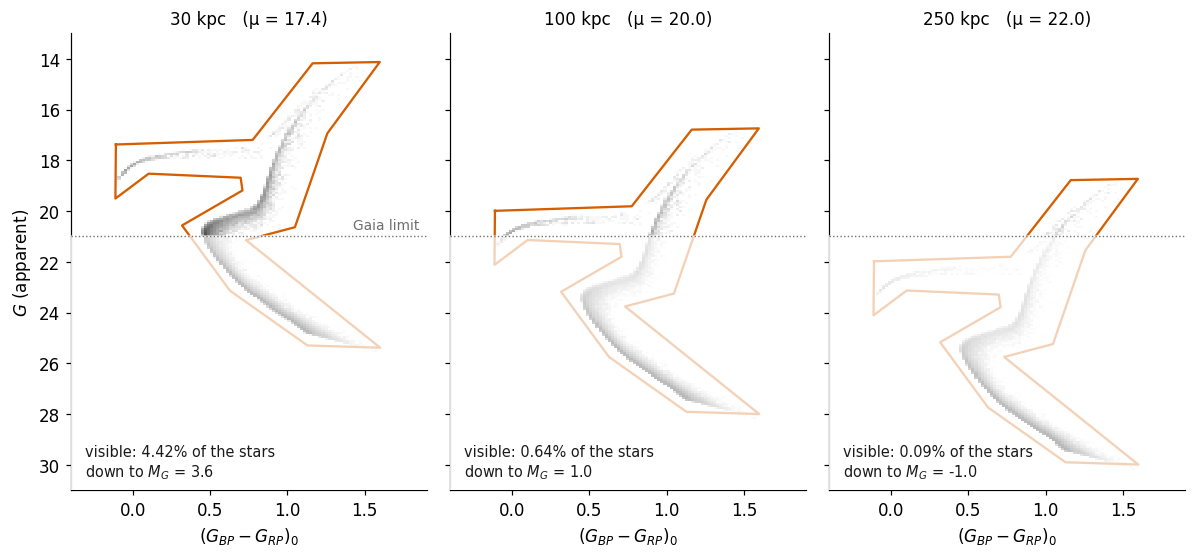

In [24]:
DISTANCES = [30, 100, 250]                                   # kpc
fig, axes = plt.subplots(1, 3, figsize=(11, 5.2), sharey=True)
for ax, d in zip(axes, DISTANCES):
    mu = 5 * np.log10(d * 1e3) - 5
    hess(ax, pop.bp_rp, pop.G + mu, ylim=(31, 13), dy=0.08)
    outline(ax, window_observed(UFD_WINDOW, mu), color=C['window'], lw=1.5)
    ax.axhspan(GAIA_LIMIT, 31, color='white', alpha=0.72, zorder=3)
    ax.axhline(GAIA_LIMIT, color=MUTED, lw=0.9, ls=':', zorder=4)
    seen = pop.G + mu < GAIA_LIMIT
    ax.set_title(f'{d} kpc   (μ = {mu:.1f})')
    ax.text(0.04, 0.03, f'visible: {seen.mean():.2%} of the stars\ndown to $M_G$ = {GAIA_LIMIT - mu:.1f}',
            transform=ax.transAxes, fontsize=9.5, color=INK, zorder=5)
    ax.set_xlabel(r'$(G_{BP}-G_{RP})_0$')
axes[0].set_ylabel(r'$G$ (apparent)')
axes[0].text(1.85, GAIA_LIMIT - 0.15, 'Gaia limit', ha='right', va='bottom', fontsize=9, color=MUTED, zorder=5)
fig.tight_layout()
save(fig, '07_window_vs_distance')

print(' d (kpc)    mu    faintest M_G seen   stars seen (of 237,000)   what is left')
for d, what in [(30, 'giants, horizontal branch, down to the turn-off'), (60, 'giants, horizontal branch, subgiants'),
                (100, 'giants and the horizontal branch'), (150, 'giants and the horizontal branch, barely'),
                (250, 'the upper giant branch only')]:
    mu = 5 * np.log10(d * 1e3) - 5
    print(f'{d:7d}  {mu:5.1f}  {GAIA_LIMIT - mu:14.1f}  {(pop.G + mu < GAIA_LIMIT).sum():16,d}          {what}')

At 30 kpc Gaia just reaches the turn-off and sees 4.4% of the stars in the file. At 100 kpc it
sees 0.6%: red giants and the horizontal branch. At 250 kpc, 0.09%: only the upper giant branch.

(The percentages are *of this file*, which already omits everything below 0.5 M☉. They show how
steeply the visible share falls, not how many stars a dwarf of a given mass would show.)

So beyond a few tens of kpc **the useful part of the window is its top third**, and most of the
polygon's area — the whole main sequence — selects nothing a Gaia star can reach.

### A wrong distance, and no distance

The window only works at the right distance modulus. Two questions, answered on the Reticulum II
field by sliding the assumed μ:

- If μ is wrong, how fast are members lost?
- If μ is unknown and has to be scanned, how many field stars get through?

The members used are those brighter than G = 19.5, so that photometric noise does not blur the
answer.

members (G < 19.5) inside at the true distance: 100%
  at least 100% stay inside for μ from 17.2 to 18.1   (28 to 42 kpc)
  at least 80% stay inside for μ from 16.0 to 19.3   (16 to 72 kpc)
  at least 50% stay inside for μ from 15.5 to 19.9   (13 to 95 kpc)
field fraction inside: 35% to 50% for every μ up to 20

field stars inside the window at the true distance : 49%
field stars inside it for SOME distance, 16 kpc to 250 kpc : 74%


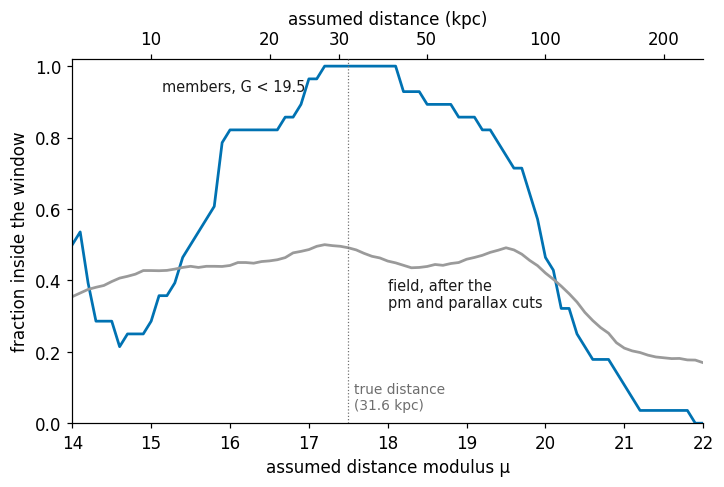

In [25]:
if HAVE_DATA:
    mus = np.arange(14.0, 22.01, 0.1)
    use = g.has_colour
    def frac_inside(sel, mu):
        s = g[sel & use]
        return in_window(*absolute_cmd(s.phot_g_mean_mag, s.phot_bp_mean_mag, s.phot_rp_mean_mag, mu, EBV),
                         UFD_WINDOW).mean()

    bright   = g.phot_g_mean_mag < 19.5
    f_member = np.array([frac_inside(g.member & bright, m) for m in mus])
    f_field  = np.array([frac_inside(~g.member & g.pm_plx, m) for m in mus])

    fig, ax = plt.subplots(figsize=(7.4, 4.3))
    ax.plot(mus, f_member, color=C['member'])
    ax.plot(mus, f_field,  color=C['field'])
    ax.axvline(RETII_MU, color=MUTED, lw=0.8, ls=':')
    ax.text(RETII_MU + 0.08, 0.04, 'true distance\n(31.6 kpc)', fontsize=9, color=MUTED)
    ax.text(mus[np.argmax(f_member)] - 0.25, 0.93, 'members, G < 19.5', color=INK, fontsize=9.5, ha='right')
    ax.text(18.0, np.interp(18.0, mus, f_field) - 0.13, 'field, after the\npm and parallax cuts', color=INK, fontsize=9.5)
    ax.set(xlabel='assumed distance modulus μ', ylabel='fraction inside the window', ylim=(0, 1.02), xlim=(mus[0], mus[-1]))
    top = ax.secondary_xaxis('top', functions=(lambda m: 10 ** (m / 5 + 1) / 1e3, lambda d: 5 * np.log10(np.maximum(d, 1e-9) * 1e3) - 5))
    top.set_xticks([10, 20, 30, 50, 100, 200]); top.set_xlabel('assumed distance (kpc)')
    save(fig, '08_wrong_distance')

    def plateau(level):
        '''The unbroken range of mu around the true value where the member fraction stays >= level.'''
        i0 = int(np.argmin(np.abs(mus - RETII_MU)))
        lo = hi = i0
        while lo > 0 and f_member[lo - 1] >= level:
            lo -= 1
        while hi < len(mus) - 1 and f_member[hi + 1] >= level:
            hi += 1
        return mus[lo], mus[hi]

    kpc = lambda m: 10 ** (m / 5 + 1) / 1e3
    print(f'members (G < 19.5) inside at the true distance: {frac_inside(g.member & bright, RETII_MU):.0%}')
    for level in (1.0, 0.8, 0.5):
        a, b = plateau(level)
        print(f'  at least {level:.0%} stay inside for μ from {a:.1f} to {b:.1f}   ({kpc(a):.0f} to {kpc(b):.0f} kpc)')
    print(f'field fraction inside: {f_field[mus <= 20].min():.0%} to {f_field[mus <= 20].max():.0%} for every μ up to 20')

    # the union over a scan of distances: what a blind search would let through
    s = g[~g.member & g.pm_plx & use]
    scan = np.arange(16.0, 22.01, 0.25)
    any_mu = np.zeros(len(s), bool)
    for m in scan:
        any_mu |= in_window(*absolute_cmd(s.phot_g_mean_mag, s.phot_bp_mean_mag, s.phot_rp_mean_mag, m, EBV), UFD_WINDOW)
    print(f'\nfield stars inside the window at the true distance : {frac_inside(~g.member & g.pm_plx, RETII_MU):.0%}')
    print(f'field stars inside it for SOME distance, 16 kpc to 250 kpc : {any_mu.mean():.0%}')

(The top axis is the same quantity as the bottom one, distance instead of distance modulus — one
scale, two labellings.)

- The member curve is a **broad plateau, not a spike.** Every bright member stays inside over
  about a magnitude of μ, and most of them over more than three — a factor of four or so in
  distance. The reason is the shape of the track: the red-giant branch is nearly vertical, so
  sliding it up or down hardly moves a giant out. Only the horizontal branch and the turn-off pin
  the distance, and few stars sit there.
- The bump at the far left is a different effect: at μ ≈ 14 the same stars are read as
  main-sequence dwarfs of a much closer population, and some land on that part of the window. **A
  star can be inside as a giant at one distance and as a dwarf at another.**
- The field curve is nearly flat: between 35% and 50% of the field is inside whatever distance
  is assumed, out to μ = 20.
- Scanned over all distances, **74% of the field passes at one distance or another**, against
  49% at the true one.

Put together: for Gaia-depth data the window is **not a distance filter**. Its rejection of the
field is nearly the same at every distance, and it does not tell a dwarf at 20 kpc from one at
60 kpc. What it removes is stars of the wrong *colour* for an old metal-poor giant or
turn-off star. Fixing μ still helps, by a third or so, and it is what makes the horizontal branch
usable.

> **Takeaway.** With distance the usable window shrinks to the giant branch and horizontal branch.
> It is forgiving of a wrong distance by a magnitude or more — which also means it constrains
> distance weakly, and scanning distance costs little selectivity.

---
## 6 · Rebuilding and changing the window

This is why the file was sent along: with the population in hand, the polygon is not a fixed
thing. Three variations, all from one small function.

### The builder

The recipe is the one a person follows by eye:

1. mark the pixels of the diagram that contain stars;
2. grow that region outward by a chosen margin in colour and in magnitude, and round it off;
3. trace the outline, and thin it to a manageable number of corners.

A simpler recipe — "at each magnitude, take the 1st to 99th percentile of colour" — fails here:
it would join the horizontal branch to the giant branch and fill the empty gap between them with
window.

In [26]:
def simplify_polygon(poly, tol):
    '''Drop corners that move the outline by less than `tol` (Ramer-Douglas-Peucker).'''
    def rdp(p):
        a, b = p[0], p[-1]
        if len(p) < 3:
            return p
        ab = b - a
        L = np.hypot(*ab)
        dist = (np.abs(ab[0] * (p[:, 1] - a[1]) - ab[1] * (p[:, 0] - a[0])) / L) if L > 0 else np.hypot(*(p - a).T)
        i = int(np.argmax(dist))
        if dist[i] <= tol:
            return np.vstack([a, b])
        return np.vstack([rdp(p[:i + 1])[:-1], rdp(p[i:])])

    p = poly[:-1] if np.allclose(poly[0], poly[-1]) else poly
    p = np.roll(p, -int(np.argmax(np.hypot(*(p - p.mean(0)).T))), axis=0)     # start at an extreme corner
    half = len(p) // 2
    return np.vstack([rdp(p[:half + 1])[:-1], rdp(np.vstack([p[half:], p[:1]]))[:-1]])


def build_window(colour, mag, pad_colour, pad_mag, *, keep=1.0, dx=0.01, dy=0.02, tol=0.01, aspect=0.2):
    '''An envelope polygon around a population in the colour-magnitude plane.

    pad_colour, pad_mag : the margin added on every side, in magnitudes
    keep : 1.0 uses every occupied pixel. Below 1, each magnitude row keeps only its densest
           pixels holding that fraction of the row's stars -- needed once the stars carry noise,
           or a single outlier would stretch the window.
    tol, aspect : corners are thinned to `tol` mag in colour, counting 1 mag in magnitude as
           `aspect` mag in colour (the diagram is much taller than it is wide).
    Returns the corners as an (n, 2) array.'''
    colour, mag = np.asarray(colour, float), np.asarray(mag, float)
    xe = np.arange(colour.min() - 3 * pad_colour - 0.1, colour.max() + 3 * pad_colour + 0.1 + dx, dx)
    ye = np.arange(mag.min() - 3 * pad_mag - 0.2, mag.max() + 3 * pad_mag + 0.2 + dy, dy)
    H = np.histogram2d(colour, mag, bins=[xe, ye])[0]

    if keep >= 1.0:
        occupied = H > 0
    else:
        order = np.argsort(-H, axis=0)                                   # densest pixel first, per row
        ranked = np.take_along_axis(H, order, axis=0)
        cum = np.cumsum(ranked, axis=0) - ranked                         # stars in denser pixels
        take = (cum < keep * H.sum(axis=0, keepdims=True)) & (ranked > 0)
        occupied = np.zeros_like(H, bool)
        np.put_along_axis(occupied, order, take, axis=0)

    rx, ry = max(int(round(pad_colour / dx)), 1), max(int(round(pad_mag / dy)), 1)
    xx, yy = np.mgrid[-rx:rx + 1, -ry:ry + 1]
    grown = ndimage.binary_dilation(occupied, structure=(xx / rx) ** 2 + (yy / ry) ** 2 <= 1.0)
    # round the outline off: without this every stray star at the edge pulls out its own spike
    grown = ndimage.gaussian_filter(grown.astype(float), sigma=(rx / 2, ry / 2)) > 0.5
    grown = ndimage.binary_fill_holes(grown)
    labels, n = ndimage.label(grown)
    if n > 1:                                                             # keep the main body only
        grown = labels == 1 + int(np.argmax(ndimage.sum(grown, labels, range(1, n + 1))))

    xc, yc = 0.5 * (xe[:-1] + xe[1:]), 0.5 * (ye[:-1] + ye[1:])
    line = max(contourpy.contour_generator(xc, yc, grown.T.astype(float)).lines(0.5), key=len)
    scale = np.array([1.0, aspect])
    return simplify_polygon(line * scale, tol) / scale


def overlap(va, vb, xlim=(-0.6, 2.2), ylim=(-4.5, 9.5), n=500):
    '''Shared area of two polygons divided by their combined area (1 = identical).'''
    X, Y = np.meshgrid(np.linspace(*xlim, n), np.linspace(*ylim, n))
    a, b = in_window(X, Y, va), in_window(X, Y, vb)
    return (a & b).sum() / (a | b).sum()

### Variation 1 — reproduce the received window

First check that the builder does what was before done by hand. Two margins: a tight one, and one
tuned to match the received polygon's area.

received                16 corners   holds 99.9954% of the population   overlap with received: 1.00
rebuilt 0.12 / 0.30     65 corners   holds 100.0000% of the population   overlap with received: 0.79
rebuilt 0.05 / 0.15     97 corners   holds 100.0000% of the population   overlap with received: 0.63


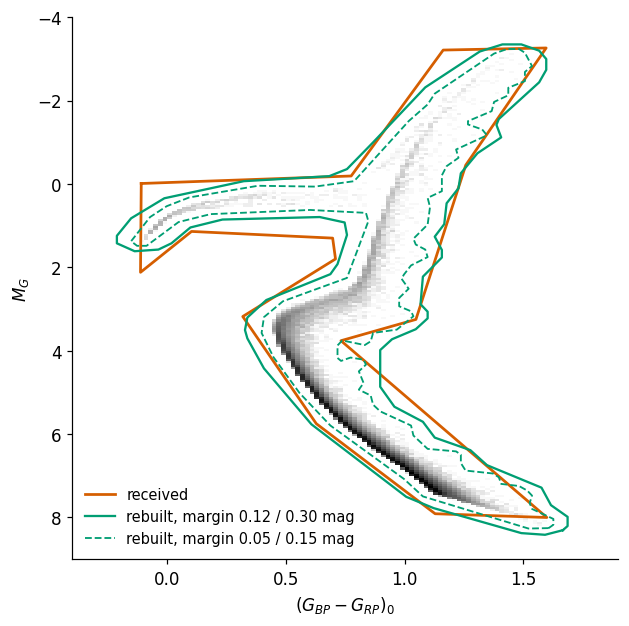

In [27]:
tight = build_window(pop.bp_rp, pop.G, 0.05, 0.15)
loose = build_window(pop.bp_rp, pop.G, 0.12, 0.30)

fig, ax = plt.subplots(figsize=(6.4, 6.4))
hess(ax, pop.bp_rp, pop.G)
outline(ax, UFD_WINDOW, color=C['window'], lw=1.8, label='received')
outline(ax, loose, color=C['alt'], lw=1.5, label='rebuilt, margin 0.12 / 0.30 mag')
outline(ax, tight, color=C['alt'], lw=1.2, ls='--', label='rebuilt, margin 0.05 / 0.15 mag')
ax.set(xlabel=r'$(G_{BP}-G_{RP})_0$', ylabel=r'$M_G$')
ax.legend(loc='lower left')
save(fig, '09_rebuilt_window')

for name, v in [('received', UFD_WINDOW), ('rebuilt 0.12 / 0.30', loose), ('rebuilt 0.05 / 0.15', tight)]:
    print(f'{name:22s} {len(v):3d} corners   holds {in_window(pop.bp_rp, pop.G, v).mean():.4%} of the population'
          f'   overlap with received: {overlap(v, UFD_WINDOW):.2f}')

The rebuilt outline follows the same track, horizontal-branch arm included, and holds the whole
population. It does **not** coincide with the received one, and it should not: the builder adds
the same margin on every side, while the hand-drawn window leaves far more room to the red than
to the blue (§3). Matching it exactly would mean an asymmetric margin — easy to add, but it is a
judgement about binaries and metallicity, not something the file dictates.

The rebuilt polygon has many more corners. That is harmless in Python; for TOPCAT, raise `tol` in
`build_window` to get a shorter expression.

### Variation 2 — a window for stars with measurement errors

§4 showed the weak point: faint members scatter out of a window drawn on perfect photometry,
because at G > 20 the colour error exceeds the window's blue margin. The fix is to give the model
stars the same errors before drawing the envelope: place the model at Reticulum II's distance,
keep what Gaia would see, scatter each star by the measured error at its magnitude (the
`colour_err` curve from §4), and draw the envelope holding 95% of the stars at each magnitude.

error-aware window: 64 corners

                                       received     error-aware
members, all                 n =    75        89%            96%
members, G < 19.5            n =    28       100%           100%
members, G > 20              n =    37        81%            95%
field after pm/parallax      n = 2,178        49%            52%


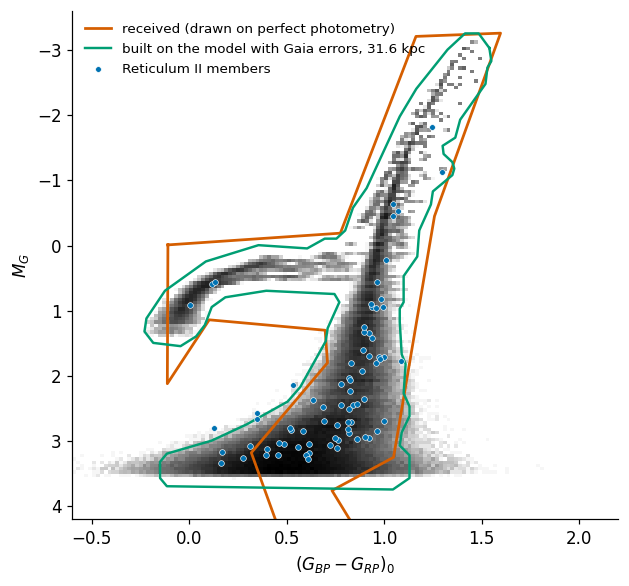

In [28]:
def observed_population(colour_name, mu, n_copies=30, limit=GAIA_LIMIT):
    '''The model population as Gaia would record it at distance modulus mu: (colour, absolute G).'''
    c = {'bp_rp': pop.BP - pop.RP, 'g_rp': pop.G - pop.RP}[colour_name].to_numpy()
    G = pop.G.to_numpy() + mu
    vis = G < limit
    c, G = np.tile(c[vis], n_copies), np.tile(G[vis], n_copies)
    c = c + RNG.normal(0, colour_err(G, colour_name))
    G = G + RNG.normal(0, colour_err(G, 'g'))
    return c, G - mu


if HAVE_DATA:
    c_obs, m_obs = observed_population('bp_rp', RETII_MU)
    # rows of 0.05 mag rather than 0.02: the 95% rule needs enough stars in each row
    noisy = build_window(c_obs, m_obs, 0.06, 0.20, keep=0.95, dy=0.05)

    fig, ax = plt.subplots(figsize=(6.4, 6.0))
    hess(ax, c_obs, m_obs, xlim=(-0.6, 2.2), ylim=(4.2, -3.6))
    outline(ax, UFD_WINDOW, color=C['window'], lw=1.8, label='received (drawn on perfect photometry)')
    outline(ax, noisy, color=C['alt'], lw=1.6, label='built on the model with Gaia errors, 31.6 kpc')
    mm = g[g.member & g.has_colour]
    ax.scatter(mm.colour0, mm.MG, s=14, color=C['member'], edgecolors='white', lw=0.4, zorder=4, label='Reticulum II members')
    ax.set(xlabel=r'$(G_{BP}-G_{RP})_0$', ylabel=r'$M_G$')
    ax.legend(loc='upper left', fontsize=8.8)
    save(fig, '10_error_aware_window')

    print(f'error-aware window: {len(noisy)} corners\n')
    g['inside_noisy'] = in_window(g.colour0, g.MG, noisy)
    print('                                       received     error-aware')
    for label, sel in [('members, all',              g.member),
                       ('members, G < 19.5',         g.member & (g.phot_g_mean_mag < 19.5)),
                       ('members, G > 20',           g.member & (g.phot_g_mean_mag > 20)),
                       ('field after pm/parallax',   ~g.member & g.pm_plx)]:
        s = g[sel & g.has_colour]
        print(f'{label:28s} n = {len(s):5,d}   {s.inside.mean():8.0%}   {s.inside_noisy.mean():12.0%}')

The error-aware window is a **funnel**: close to the model where Gaia is precise, flaring toward
the faint limit. The table above is the comparison on Reticulum II. It keeps every bright member
and raises the faint-member recovery from 81% to 95%, **for three percentage points more field**
(49% → 52%). The cost is small because the funnel is narrower than the received window wherever
Gaia is precise, and gives that area back.

With the margins used here (0.06 mag in colour, 0.2 in magnitude) it still holds the bright
giants. Make the margin much smaller and it starts to lose real giants that sit a little redward
of the model track — stars the received window's generous red margin keeps. The two windows answer different worries — the received one, that the model is not quite
right; this one, that the photometry is noisy. A margin for both is `pad_colour`.

Note that this window is tied to **one distance**. The flare sits at Gaia's limit in *apparent*
magnitude, so at a different μ it lands on a different part of the track. It has to be rebuilt
for each distance, which `observed_population(colour, mu)` + `build_window` does in a second.

### Variation 3 — another colour

The window can be redrawn in any colour the file has. The natural alternative is G − RP: the BP
band is the noisiest of the three for faint red stars, so G − RP is measured more precisely
(figure above), at the price of a shorter colour baseline — the track is narrower too.

how well each colour separates the turn-off from the base of the giant branch, at Reticulum II:
  BP - RP  colour difference 0.362 mag   error at G = 20.5: 0.174 mag   ratio  2.1
  G - RP   colour difference 0.202 mag   error at G = 20.5: 0.074 mag   ratio  2.8


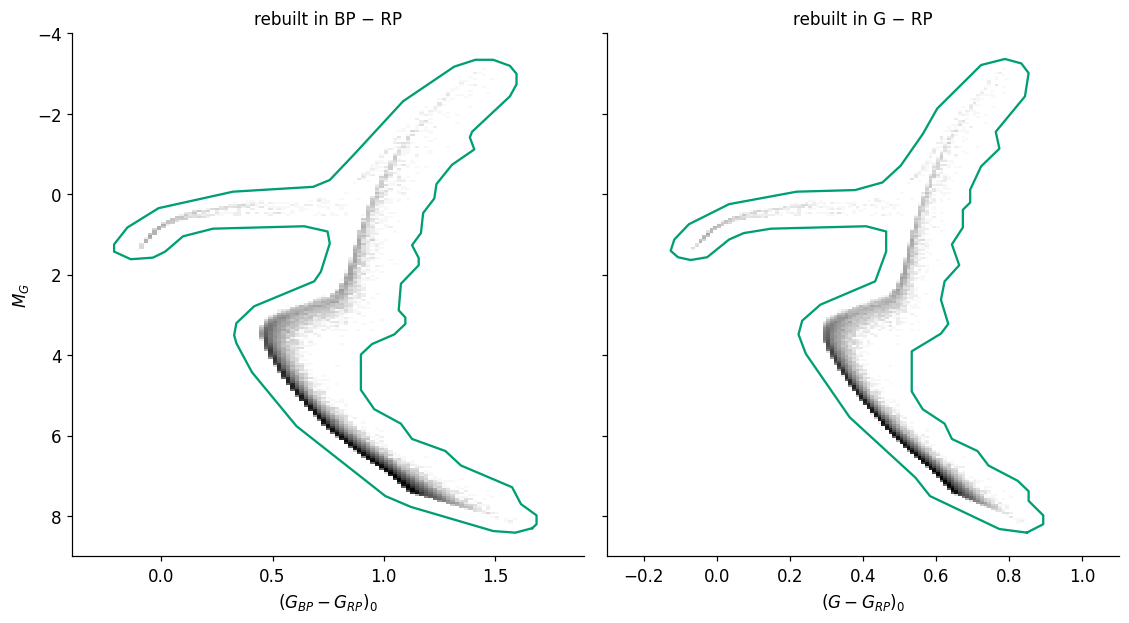

In [29]:
pop['g_rp'] = pop.G - pop.RP
win_grp = build_window(pop.g_rp, pop.G, 0.06, 0.30)

fig, (ax, bx) = plt.subplots(1, 2, figsize=(10.4, 5.8), sharey=True)
hess(ax, pop.bp_rp, pop.G);                       outline(ax, loose,   color=C['alt'], lw=1.5)
hess(bx, pop.g_rp,  pop.G, xlim=(-0.3, 1.1), dx=0.01); outline(bx, win_grp, color=C['alt'], lw=1.5)
ax.set(xlabel=r'$(G_{BP}-G_{RP})_0$', ylabel=r'$M_G$', title='rebuilt in BP − RP')
bx.set(xlabel=r'$(G-G_{RP})_0$', title='rebuilt in G − RP')
fig.tight_layout()
save(fig, '11_window_in_g_rp')

# is the trade worth it?  colour separation between turn-off and giant-branch base, in units of the error
if HAVE_DATA:
    print('how well each colour separates the turn-off from the base of the giant branch, at Reticulum II:')
    for name, lab in [('bp_rp', 'BP - RP'), ('g_rp', 'G - RP')]:
        to  = pop.loc[(pop.G > 3.4) & (pop.G < 3.7), name].median()
        rgb = pop.loc[(pop.G > 2.0) & (pop.G < 2.4) & (pop.bp_rp > 0.75), name].median()
        e   = colour_err(3.0 + RETII_MU, name)
        print(f'  {lab:8s} colour difference {rgb - to:5.3f} mag   error at G = {3.0 + RETII_MU:.1f}: {e:5.3f} mag'
              f'   ratio {(rgb - to) / e:4.1f}')

The last lines are the number that decides it: the colour difference between two parts of the
track, divided by the measurement error at that brightness. At G = 20.5 the ratio is 2.8 for
G − RP against 2.1 for BP − RP: the track is 45% narrower in G − RP, but the error is 57% smaller,
so **G − RP separates stars better near Gaia's limit**. At bright magnitudes, where both errors
are negligible, the longer baseline of BP − RP wins. The comparison is specific to the magnitude
where it is made — repeat it at the brightness of the stars you care about.

To use a G − RP window on data, de-redden with `(R_EXT['G'] - R_EXT['RP']) * E(B-V)` instead of
the BP − RP term; everything else is unchanged.

> **Takeaway.** With the file, the window is a recipe rather than a fixed polygon: change the
> margin, fold in the errors for a given distance, or switch colour, with one function.

---
## 7 · Limits

**What the window cannot do**

- **One kind of population.** 12–13 Gyr, [Fe/H] ≈ −2.3. A dwarf with younger or more metal-rich
  stars (the classical dwarfs, anything with extended star formation) has stars redward and
  brightward of this track. The red margin covers some of that; it was not designed to.
- **No binaries, no errors** in the model. The received polygon's margins stand in for both.
- **It needs a distance.** Scanned over distance it rejects little (§5).
- **It needs a reddening.** Trivial at high latitude, not elsewhere (§4).
- **It needs a colour.** Gaia sources without BP or RP are silently outside.
- **Checked on one dwarf.** Whether the model's colours match real stars elsewhere is assumed,
  not shown here.
- **Below M_G ≈ 8 the file is empty**, so the window says nothing about fainter dwarf stars
  (irrelevant for Gaia beyond a few kpc).

Three small files, written below: the corners as a table, a standalone Python
file with the two functions and the corners, and a note. The Python file is generated from the
functions defined above, so there is one copy of the logic.

In [30]:
WORK.mkdir(parents=True, exist_ok=True)

# 1. the corners
pd.DataFrame(UFD_WINDOW, columns=['bp_rp_0', 'M_G']).to_csv(WORK / 'ufd_cmd_window_vertices.csv', index=False)

# 2. a standalone module: numpy + matplotlib only
docstring = '''Colour-magnitude window for ultra-faint dwarfs in Gaia photometry.

A polygon in de-reddened colour (BP-RP)_0 against absolute magnitude M_G, drawn around the
synthetic old, metal-poor population (12-13 Gyr, [Fe/H] = -2.3 +/- 0.5) used in
Battaglia et al. 2022 (A&A 657, A54). Needs a distance modulus and a reddening per star or field.

    colour0, MG = absolute_cmd(G, BP, RP, dist_mod=17.5, ebv=0.016)
    keep = in_window(colour0, MG, UFD_WINDOW)

Generated by ufd_cmd_window.ipynb.
'''
module = '"' * 3 + docstring + '"' * 3 + f'''
import numpy as np
from matplotlib.path import Path as Polygon

# corners, as ((BP-RP)_0, M_G)
UFD_WINDOW = np.array({np.array2string(UFD_WINDOW, separator=', ', floatmode='fixed', precision=3)})

# extinction per unit E(B-V): A_X = R_X * E(B-V)   (Casagrande & VandenBerg 2018)
R_EXT = {R_EXT!r}

TOPCAT_EXPR = {TOPCAT_EXPR!r}


{inspect.getsource(absolute_cmd)}

{inspect.getsource(in_window)}'''
(WORK / 'ufd_cmd_window.py').write_text(module)

# 3. the note
(WORK / 'README.md').write_text(f'''# A colour-magnitude window for ultra-faint dwarfs (Gaia)

A selection polygon in the Gaia colour-magnitude diagram for old, metal-poor populations.

- **x** = (BP - RP)_0, de-reddened colour.  **y** = M_G, absolute G magnitude.
- {len(UFD_WINDOW)} corners, in `ufd_cmd_window_vertices.csv`.
- TOPCAT, for the synthetic file itself (col10 = G, col11 = BP, col12 = RP):

      {TOPCAT_EXPR}

- Python: `ufd_cmd_window.py` (numpy and matplotlib only).

## Before applying it

The window is defined on absolute magnitude and de-reddened colour, so data need

1. a **distance modulus**:  M_G = G - A_G - mu
2. an **extinction correction**:  (BP-RP)_0 = (BP-RP) - (A_BP - A_RP)

## Where it comes from

Drawn around a synthetic population: constant star formation 12-13 Gyr ago, [Fe/H] = -2.3 with
sigma 0.5, {len(pop):,} stars, Gaia G / BP / RP absolute magnitudes (`{DAT.name}`). It is the
population used in Battaglia et al. 2022 (A&A 657, A54). The window holds
{pop.inside.sum():,} of those stars. Received from colleagues at the IAC, October 2026.

## Limits

- One population: no younger or metal-rich stars.
- The model has no binaries and no photometric errors; near Gaia's faint limit real members
  scatter out of the window.
- Stars without a BP or RP magnitude cannot be tested and count as outside.
- The file stops at 0.5 Msun (M_G = 8.15).
''')

# the exported file must give exactly what the notebook's functions give
spec = importlib.util.spec_from_file_location('ufd_cmd_window', WORK / 'ufd_cmd_window.py')
mod = importlib.util.module_from_spec(spec); spec.loader.exec_module(mod)
assert np.array_equal(mod.UFD_WINDOW, UFD_WINDOW)
assert np.array_equal(mod.in_window(pop.bp_rp, pop.G, mod.UFD_WINDOW), pop.inside)
c_a, m_a = mod.absolute_cmd(15.0, 15.5, 14.4, 17.5, 0.02)
c_b, m_b = absolute_cmd(15.0, 15.5, 14.4, 17.5, 0.02)
assert c_a == c_b and m_a == m_b

for f in sorted(WORK.glob('*.*')):
    print(f'wrote {f}   ({f.stat().st_size:,} bytes)')

wrote ../../materials/ufd_cmd_window/README.md   (1,549 bytes)
wrote ../../materials/ufd_cmd_window/ufd_cmd_window.py   (2,214 bytes)
wrote ../../materials/ufd_cmd_window/ufd_cmd_window_vertices.csv   (189 bytes)


### Using the exported file

```python
import numpy as np
from ufd_cmd_window import UFD_WINDOW, absolute_cmd, in_window

# G, BP, RP: observed Gaia magnitudes of your stars
colour0, MG = absolute_cmd(G, BP, RP, dist_mod=17.5, ebv=0.016)
keep = in_window(colour0, MG, UFD_WINDOW)
```